# Definitions: numerator, denominator, window, exclusions: which four lines make a number computable, and how does each line move it?

**Week 4, Monday, chapter 4 of 11, concept chapter 4 of 6.** The topic, in the curriculum's words: *Definitions: numerator, denominator, window, exclusions*. Every number in this notebook is invented for the chapter and small enough to count by hand. It is read from a table the day's generator wrote to `data/`, and the code only confirms the count.

**Who needs the answer.** A school principal (invented), who prints one attendance figure on a student's transfer certificate, and the two clerks who must compute it alike: a figure computed two ways can cost a student a scholarship. After the break, the Uber analyst whose `driver_weeks` table counts offers while `zone_weeks` counts rider requests, two units for the same riders.

**The questions on the way.**

1. What does the register hold?
2. How many different numbers can five honest clerks get from it?
3. Which line moved each reading?
4. Can one short function hold all four lines and reproduce every reading?
5. What does a certificate printed on the wrong line cost?
6. What do the last 20 working days read with medical leave left out, in your turn?

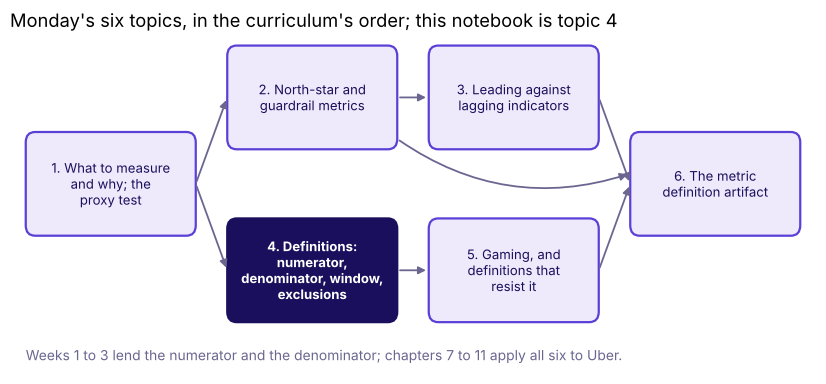

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

def check(name, ok):
    print("PASS" if ok else "FAIL", name)

plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "font.size": 11})
INK, VIOLET, ROSE, LAV, MUTED = "#1A0F5C", "#5B3FD6", "#D63A6A", "#D9A7FF", "#6B6690"

from matplotlib.patches import FancyBboxPatch, Patch

TOPICS = ["1. What to measure\nand why; the\nproxy test", "2. North-star and\nguardrail metrics",
          "3. Leading against\nlagging indicators", "4. Definitions:\nnumerator,\ndenominator, window,\nexclusions",
          "5. Gaming, and\ndefinitions that\nresist it", "6. The metric\ndefinition artifact"]
PLACE = [(1.6, 2.25), (4.8, 3.5), (8.0, 3.5), (4.8, 1.0), (8.0, 1.0), (11.2, 2.25)]
LINKS = [(0, 1), (1, 2), (0, 3), (3, 4), (2, 5), (4, 5)]


def topic_map(lit):
    """Monday's six topics in the curriculum's order, joined as the deck's concept map joins them."""
    fig, ax = plt.subplots(figsize=(10.4, 4.4))
    w, h = 2.7, 1.5
    for a, b in LINKS:
        (xa, ya), (xb, yb) = PLACE[a], PLACE[b]
        ax.annotate("", xy=(xb - w / 2, yb), xytext=(xa + w / 2, ya),
                    arrowprops={"arrowstyle": "-|>", "color": MUTED, "lw": 1.3})
    (x2, y2), (x6, y6) = PLACE[1], PLACE[5]   # chapter 2's guardrails feed the page, curved under box 3
    ax.annotate("", xy=(x6 - w / 2, y6 + 0.15), xytext=(x2 + w / 2, y2 - 0.6),
                arrowprops={"arrowstyle": "-|>", "color": MUTED, "lw": 1.3, "connectionstyle": "arc3,rad=0.25"})
    for i, ((x, y), label) in enumerate(zip(PLACE, TOPICS), start=1):
        on = i == lit
        ax.add_patch(FancyBboxPatch((x - w / 2, y - h / 2), w, h, boxstyle="round,pad=0,rounding_size=0.15",
                                    fc=INK if on else "#EEEAFB", ec=INK if on else VIOLET, lw=1.6))
        ax.text(x, y, label, ha="center", va="center", fontsize=9.5, color="white" if on else INK,
                fontweight="bold" if on else "normal")
    ax.text(0.25, -0.3, "Weeks 1 to 3 lend the numerator and the denominator; chapters 7 to 11 apply all six to Uber.",
            fontsize=10, color=MUTED)
    ax.set_xlim(0, 12.8)
    ax.set_ylim(-0.5, 4.4)
    ax.axis("off")
    ax.set_title(f"Monday's six topics, in the curriculum's order; this notebook is topic {lit}", loc="left")
    plt.show()

topic_map(4)

## What does the register hold?

Week 1 Monday wrote every rate as a numerator over a denominator; this chapter adds the two lines
Week 1 left implicit. The example is one student's 60-day term (invented): each day is present,
absent, on medical leave, or a school holiday. This cell loads the register, prints all 60 days
as six rows of ten, and draws them one square a day.

One student's 60-day term, every day invented for this chapter (P present, A absent, M medical, H holiday):
days  1 to 10: P P P P A P H P P P
days 11 to 20: P P A H P P P H P P
days 21 to 30: H A P P P P P H P A
days 31 to 40: P P P P H P P P A P
days 41 to 50: P H P P H A P P H M
days 51 to 60: M P A P P H P P A P
status
present    40
holiday    10
absent      8
medical     2


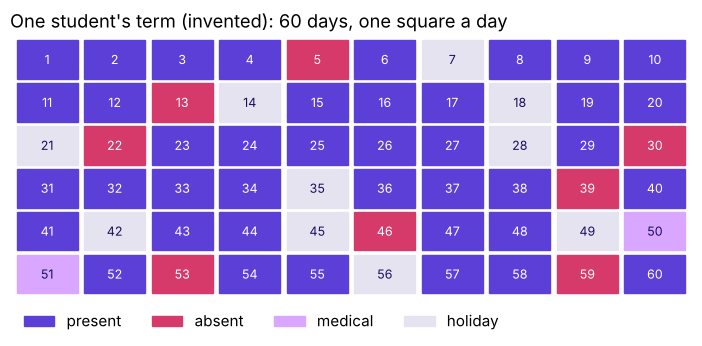

PASS 60 days with 10 holidays, so 50 working days
PASS 40 present, 8 absent and 2 on medical leave


In [2]:
reg = pd.read_csv("../data/C2_W04_D01_attendance_register_STUDENT.csv")
LETTER = {"present": "P", "absent": "A", "medical": "M", "holiday": "H"}
print("One student's 60-day term, every day invented for this chapter (P present, A absent, M medical, H holiday):")
for start in range(0, 60, 10):
    print(f"days {start + 1:>2} to {start + 10:>2}: " + " ".join(LETTER[s] for s in reg["status"].iloc[start:start + 10]))
print(reg["status"].value_counts().to_string())
COLOUR = {"present": VIOLET, "absent": ROSE, "medical": LAV, "holiday": "#E6E3F0"}
fig, ax = plt.subplots(figsize=(8.8, 3.4))
for i, status in enumerate(reg["status"]):
    ax.add_patch(plt.Rectangle((i % 10, 5 - i // 10), 0.9, 0.9, color=COLOUR[status]))
    ax.text(i % 10 + 0.45, 5 - i // 10 + 0.45, str(i + 1), ha="center", va="center", fontsize=9,
            color="white" if status in ("present", "absent") else INK)
ax.set_xlim(-0.1, 10)
ax.set_ylim(-0.1, 6)
ax.axis("off")
ax.legend(handles=[Patch(color=c, label=s) for s, c in COLOUR.items()], frameon=False, ncol=4,
          loc="upper left", bbox_to_anchor=(0, 0))
ax.set_title("One student's term (invented): 60 days, one square a day", loc="left")
plt.show()
check("60 days with 10 holidays, so 50 working days", len(reg) == 60 and (reg["status"] == "holiday").sum() == 10)
check("40 present, 8 absent and 2 on medical leave",
      reg["status"].value_counts()[["present", "absent", "medical"]].tolist() == [40, 8, 2])

## How many numbers can one honest register give?

**Predict before you run.** Five honest clerks compute the student's attendance percentage from
this one register, each reading the school's rule in their own way. How many different numbers
come out?

a) One, since a register is a register.
b) Two: with holidays, or without them.
c) Four or more: one for each choice a clerk makes.
d) It cannot be told without the register in hand.

The next cell counts five readings by hand, one line each, then counts each by filtering the
table directly, and checks that the two agree.

In [3]:
# By hand, one reading a line: 100 x numerator / denominator
hand = {"the school's rule: present over working days": 100 * 40 / 50,          # 80.0
        "denominator: present over calendar days": 100 * 40 / 60,                # 66.7
        "exclusions: medical leave out of both counts": 100 * 40 / 48,           # 83.3
        "numerator: medical leave counted present": 100 * 42 / 50,               # 84.0
        "window: the last 20 working days": 100 * 14 / 20}                       # 70.0

# By code, filtering the table directly for each reading
def present(d):
    return int((d["status"] == "present").sum())

work = reg[reg["status"] != "holiday"]
last20 = work.tail(20)
direct = {"the school's rule: present over working days": 100 * present(work) / len(work),
          "denominator: present over calendar days": 100 * present(reg) / len(reg),
          "exclusions: medical leave out of both counts": 100 * present(work) / (work["status"] != "medical").sum(),
          "numerator: medical leave counted present": 100 * work["status"].isin(["present", "medical"]).sum() / len(work),
          "window: the last 20 working days": 100 * present(last20) / len(last20)}
for k in hand:
    print(f"{k:<46} by hand {hand[k]:5.1f}   by code {direct[k]:5.1f}")
print(f"the first 30 working days held {present(work.head(30))} present days; the last 20 held {present(last20)}")
check("hand and code agree on all five readings", all(round(hand[k], 1) == round(direct[k], 1) for k in hand))
check("five different readings, from 66.7 to 84.0, out of one register", len({round(v, 1) for v in direct.values()}) == 5)

the school's rule: present over working days   by hand  80.0   by code  80.0
denominator: present over calendar days        by hand  66.7   by code  66.7
exclusions: medical leave out of both counts   by hand  83.3   by code  83.3
numerator: medical leave counted present       by hand  84.0   by code  84.0
window: the last 20 working days               by hand  70.0   by code  70.0
the first 30 working days held 26 present days; the last 20 held 14
PASS hand and code agree on all five readings
PASS five different readings, from 66.7 to 84.0, out of one register


**What happened.** The answer is c: five numbers, each honest, each answering a different
question. 80.0 counts present days over the 50 working days; 66.7 divides by all 60 calendar
days, holidays included; 83.3 leaves the two medical days out of both counts, an exclusion; 84.0
changes the numerator, counting them as present; 70.0 reads only the term's last 20 working days. The window matters on its own: the
first 30 working days held 26 present days and the last 20 only 14.

Named last: four lines make a number computable. The **numerator** is what is counted on top;
the **denominator**, what it is divided by; the **window**, the stretch of time the count
covers; the **exclusions**, what leaves both counts, with the date of any change. With the four
written down, two clerks compute the same number. A count, such as licences in a year, has no
denominator; in its place it says what one unit is and how repeats are removed.

## Can one short function hold the four lines?

This cell writes the definition as a function, the one the deck shows. Its two arguments are the
numerator and the denominator, each a list of the statuses it counts; the window is the rows
passed in; an exclusion is a status left out of both lists. It reproduces the five readings and
draws them against a 75 percent line.

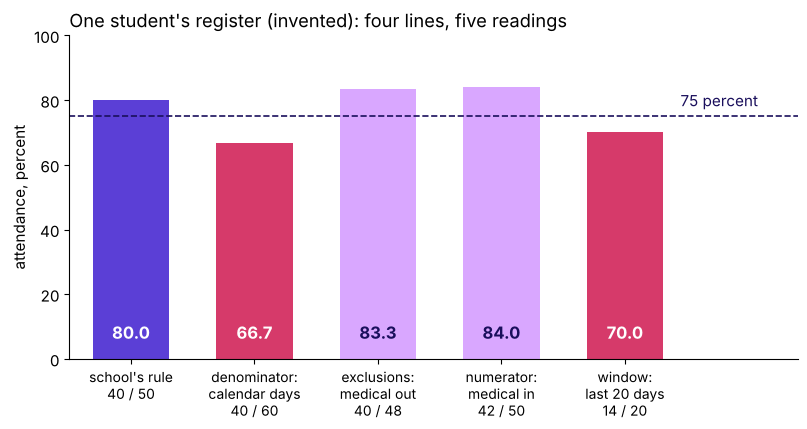

PASS the function reproduces the five readings counted directly
PASS two of the five readings fall below a 75 percent line


In [4]:
def attendance(days, top=("present",), bottom=("present", "absent", "medical")):
    """Attendance in percent: days whose status is in top, over days whose status is in bottom."""
    return round(100 * days["status"].isin(top).sum() / days["status"].isin(bottom).sum(), 1)

readings = {"school's rule\n40 / 50": attendance(reg),
            "denominator:\ncalendar days\n40 / 60": attendance(reg, bottom=("present", "absent", "medical", "holiday")),
            "exclusions:\nmedical out\n40 / 48": attendance(reg, bottom=("present", "absent")),
            "numerator:\nmedical in\n42 / 50": attendance(reg, top=("present", "medical")),
            "window:\nlast 20 days\n14 / 20": attendance(work.tail(20))}
fig, ax = plt.subplots(figsize=(9.4, 4.2))
bar_colours = [VIOLET, ROSE, LAV, LAV, ROSE]
ax.bar(range(5), list(readings.values()), color=bar_colours, width=0.62)
for i, v in enumerate(readings.values()):
    ax.text(i, 5, f"{v:.1f}", ha="center", va="bottom", fontweight="bold", fontsize=12,
            color=INK if bar_colours[i] == LAV else "white")
ax.axhline(75, color=INK, linestyle="--", lw=1.2)
ax.text(4.45, 77, "75 percent", va="bottom", color=INK)
ax.set_xlim(-0.5, 5.4)
ax.set_xticks(range(5), list(readings), fontsize=10)
ax.set_ylim(0, 100)
ax.set_ylabel("attendance, percent")
ax.set_title("One student's register (invented): four lines, five readings", loc="left")
plt.show()
check("the function reproduces the five readings counted directly",
      list(readings.values()) == [round(v, 1) for v in direct.values()])
check("two of the five readings fall below a 75 percent line", sum(v < 75 for v in readings.values()) == 2)

## What does a certificate printed on the wrong line cost?

Suppose a scholarship (invented) asks for attendance of 75 percent or more. The clerk who divides
by calendar days prints 66.7 and the student loses it; the clerk who follows the school's rule
prints 80.0 and the student keeps it; a clerk who reads only the last 20 working days prints
70.0. The check that catches the wrong number is the denominator and the window lines. The fix
is to print the definition beside the number wherever it travels: present days over working
days, the whole term, medical days kept in the denominator and out of the numerator.

### Your turn: what do the last 20 working days read with medical leave left out?

In the term's last 20 working days the student was present on 14, absent on 4 and on medical
leave for 2. A clerk leaves the medical days out of both counts. In the empty cell below, fill
the two blanks and run it:

```python
last_20 = reg[reg["status"] != "holiday"].tail(____)
window_medical_out = attendance(last_20, bottom=(____))
```

The check under it compares your number with the reference at one decimal, and shows the
reference only once your number exists.

In [5]:
mine = globals().get("window_medical_out")
if mine is None:
    print("Store window_medical_out in the empty cell above, then run this cell again.")
else:
    ref = attendance(reg[reg["status"] != "holiday"].tail(20), bottom=("present", "absent"))
    print(f"reference: {ref:.1f}; yours: {mine:.1f}")
    print("matches at one decimal" if abs(mine - ref) <= 0.05 else "not yet: which statuses stay in the denominator?")

Store window_medical_out in the empty cell above, then run this cell again.


## What does chapter 4 leave?

1. The register (invented) holds 60 days: 10 holidays, 40 present, 8 absent and 2 on medical leave.
2. Five honest clerks can print five numbers from it, from 66.7 to 84.0 percent.
3. The denominator moved it to 66.7, the exclusions to 83.3, the numerator to 84.0 and the
   window to 70.0.
4. One function, `attendance(days, top, bottom)`, holds the four lines and reproduces all five.
5. Printed on the wrong line, the same student loses a scholarship set at 75 percent.

**The rules.**

- Write the numerator and the denominator as counts of named things.
- Write the window as dates or periods: the same register reads 80.0 over the term and 70.0 over
  its last 20 working days.
- List every exclusion, and date any change to the list.
- Print the definition beside the number wherever the number travels.

**In the interview.** [F] What makes a metric gameable, and how do you write one that is not?

**The published form.** Swiggy's shareholder letters define a monthly transacting user as a
unique user with at least one completed order in the month, averaged over the period, so a
reader cannot mistake it for registered users. In February 2018 Delhi Metro carried nearly 27
lakh riders a day; its new "line utilisation" count read 45,35,932 on 29 May 2018, because a
rider who changes across three lines counts three times: one crowd, two units, and two windows
too. After the change it did not share the daily ridership figure.

**Where it goes next.** Notebook 05 asks what the four lines must resist. After the break,
`C2_W04_D01_08_denominators_on_full_data_STUDENT.ipynb` writes the four lines for all 12,860
Uber driver-weeks, where offers and rider requests count the same riders in two units.